In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt

In [2]:
df=pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
numerical_columns = list(df.dtypes[df.dtypes=='float64'].index)+list(df.dtypes[df.dtypes=='int64'].index)
numerical_columns.remove('converted')

In [4]:
df.annual_income=df.annual_income.fillna(0)
df.lead_score=df.lead_score.fillna(0)

for c in categorical_columns:
    df[c]=df[c].fillna('NA')

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [7]:
y_train=df_train.converted.values
y_val=df_val.converted.values
y_test=df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [8]:
AUC_num={}
for num in numerical_columns:
    AUC_num[num]=roc_auc_score(y_train, df_train[num])

In [9]:
AUC_num

{'annual_income': 0.6081977776250831,
 'lead_score': 0.7882254810906102,
 'number_of_courses_viewed': 0.7229894623989618,
 'interaction_count': 0.7649203047563227}

In [10]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical_columns + numerical_columns].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

val_dict = df_val[categorical_columns + numerical_columns].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
round(roc_auc_score(y_val, y_pred),3)

0.732

In [11]:
tresholds=np.arange(0.0, 1.01, 0.01).tolist()
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)
scores=[]

for t in tresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum() 
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    p = tp / (tp + fp)
    r = tp / (tp + fn)
    scores.append((t, p, r))
columns = ['threshold', 'precision', 'recall']
df_scores = pd.DataFrame(scores, columns=columns)

C:\Users\gabi\AppData\Local\Temp\ipykernel_3944\58533032.py:15: RuntimeWarning: invalid value encountered in scalar divide
  p = tp / (tp + fp)


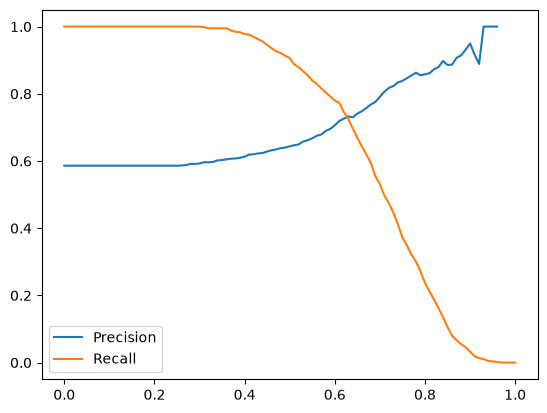

In [12]:
plt.plot(df_scores.threshold, df_scores['precision'], label='Precision')
plt.plot(df_scores.threshold, df_scores['recall'], label='Recall')
plt.legend()

In [13]:
df_scores['Q3']=abs(df_scores.precision-df_scores.recall)
df_scores.iloc[df_scores.Q3.idxmin()]

threshold    0.630000
precision    0.732759
recall       0.725256
Q3           0.007503
Name: 63, dtype: float64

In [14]:
df_scores['f1']=2*((df_scores.precision*df_scores.recall)/(df_scores.precision+df_scores.recall))
df_scores.iloc[df_scores.f1.idxmax()]

threshold    0.410000
precision    0.619048
recall       0.976109
Q3           0.357062
f1           0.757616
Name: 41, dtype: float64

In [15]:
def train(df_train, y_train, df_val, C=1.0):
    dicts = df_train[categorical_columns + numerical_columns].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    dicts_val = df_val[categorical_columns + numerical_columns].to_dict(orient='records')

    X = dv.transform(dicts_val)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [16]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    y_pred = train(df_train, y_train, df_val)
    
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

In [17]:
round(np.std(scores),3)

np.float64(0.007)

In [18]:
from tqdm.auto import tqdm

In [19]:
for C in tqdm([0.000001, 0.001, 1]):
    kfold =KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        y_pred = train(df_train, y_train, df_val, C=C)
        
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
